

```
`# This is formatted as code`
```

# Import Modules for Data Analysis

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc
import sklearn as sk
import seaborn as sns
%matplotlib inline

# For Filtering the warnings
import warnings
warnings.filterwarnings('ignore')

# 1. DATA ACQUISION

In [ ]:
df_ncd = pd.read_csv('/content/bgd2018.csv')

#### 1.1 Scanning the dataframe

In [ ]:
df_ncd.head()

,pid,psu,stratum,division,urbanrural,wstep1,wstep2,wstep3,agerange,sex,...,b5,b6,b8,b9,b10,b14,b15,b16,b17,ldl
0,E11-1-1,1,102,1,Urban,2289.934,2289.934,2225.453,18-29,0,...,97.000,NaN,179.000,NaN,2.000,37.600,30.000,105.000,37.000,121.000
1,E11-10-1,1,102,1,Urban,1202.909,1202.909,NaN,45-59,0,...,NaN,2.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E11-100-1,48,101,1,Rural,7604.362,7604.362,12915.716,30-44,0,...,100.000,NaN,168.000,NaN,2.000,21.000,15.000,140.000,29.000,111.000
3,E11-101-1,49,101,1,Rural,7710.942,7710.942,7493.812,18-29,0,...,90.000,NaN,134.000,NaN,2.000,29.000,20.000,68.000,43.000,77.400
4,E11-102-1,49,101,1,Rural,4049.076,4049.076,6877.199,30-44,0,...,99.000,NaN,231.000,NaN,2.000,235.000,120.000,235.000,33.000,151.000


In [ ]:
df_ncd.shape

(8185, 425)

In [ ]:
columns_to_keep = ['b16', 'm11', 'm12', 'h19', 'm16c', 'h17', 'h9', 'dx6', 'h7a', 'h2a', 'h13a', 't1', 'urbanrural', 'm6a', 'm6b', 'sex', 'a1', 'age', 'division', 'b5', 'b8', 'b17', 'ldl', ]

df_ncd = df_ncd[columns_to_keep]

In [ ]:
df_ncd.rename(columns={'b16': 'triglycerides', 'm11': 'height', 'm12': 'weight', 'h19': 'currently taking statins', 'm16c': 'heart rate', 'h17': 'had heart attack or stroke', 'h9': 'taking insulin', 'dx6': 'oil-used', 'h7a': 'had high glucose', 'h2a': 'had high BP', 'h13a': 'had high Cholesterol', 't1': 'current smooking', 'm6b': 'diastolic', 'm6a': 'systolic', 'a1': 'ever drank alcohol', 'b5': 'fasting blood glucose', 'b8': 'cholesterol', 'b17': 'hdl'}, inplace=True)

In [ ]:
df_ncd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8185 entries, 0 to 8184
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   triglycerides               7199 non-null   float64
 1   height                      8018 non-null   float64
 2   weight                      8018 non-null   float64
 3   currently taking statins    8185 non-null   int64  
 4   heart rate                  8154 non-null   float64
 5   had heart attack or stroke  8185 non-null   int64  
 6   taking insulin              538 non-null    float64
 7   oil-used                    8185 non-null   int64  
 8   had high glucose            2386 non-null   float64
 9   had high BP                 6060 non-null   float64
 10  had high Cholesterol        514 non-null    float64
 11  current smooking            8185 non-null   int64  
 12  urbanrural                  8185 non-null   object 
 13  systolic                    8154 

In [ ]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)
df_ncd.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
triglycerides,7199.000,146.602,101.136,0.000,85.000,123.000,180.000,1364.000
height,8018.000,157.048,20.359,100.200,150.000,156.000,163.000,888.000
weight,8018.000,57.218,23.855,28.000,48.000,55.000,64.000,888.000
currently taking statins,8185.000,1.979,0.143,1.000,2.000,2.000,2.000,2.000
heart rate,8154.000,78.043,12.205,31.000,70.000,77.000,86.000,136.000
had heart attack or stroke,8185.000,1.895,0.307,1.000,2.000,2.000,2.000,2.000
taking insulin,538.000,1.797,0.402,1.000,2.000,2.000,2.000,2.000
oil-used,8185.000,1.281,0.898,1.000,1.000,1.000,1.000,9.000
had high glucose,2386.000,1.775,0.418,1.000,2.000,2.000,2.000,2.000
had high BP,6060.000,1.767,0.422,1.000,2.000,2.000,2.000,2.000


# 2. Filtering Dataset

In [ ]:
df_ncd.shape

(8185, 23)

In [ ]:
df_ncd.isnull()

,triglycerides,height,weight,currently taking statins,heart rate,had heart attack or stroke,taking insulin,oil-used,had high glucose,had high BP,...,systolic,diastolic,sex,ever drank alcohol,age,division,fasting blood glucose,cholesterol,hdl,ldl
0,False,False,False,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,True,True,True
2,False,False,False,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8180,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8181,False,False,False,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
8182,False,False,False,False,False,False,True,False,True,True,...,False,False,False,False,False,False,False,False,False,False
8183,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
df_ncd.isnull().sum()/len(df_ncd)*100

,0
triglycerides,12.046
height,2.040
weight,2.040
currently taking statins,0.000
heart rate,0.379
had heart attack or stroke,0.000
taking insulin,93.427
oil-used,0.000
had high glucose,70.849
had high BP,25.962


#### 1.3 Detecting Missing Values

In [ ]:
import missingno as msno

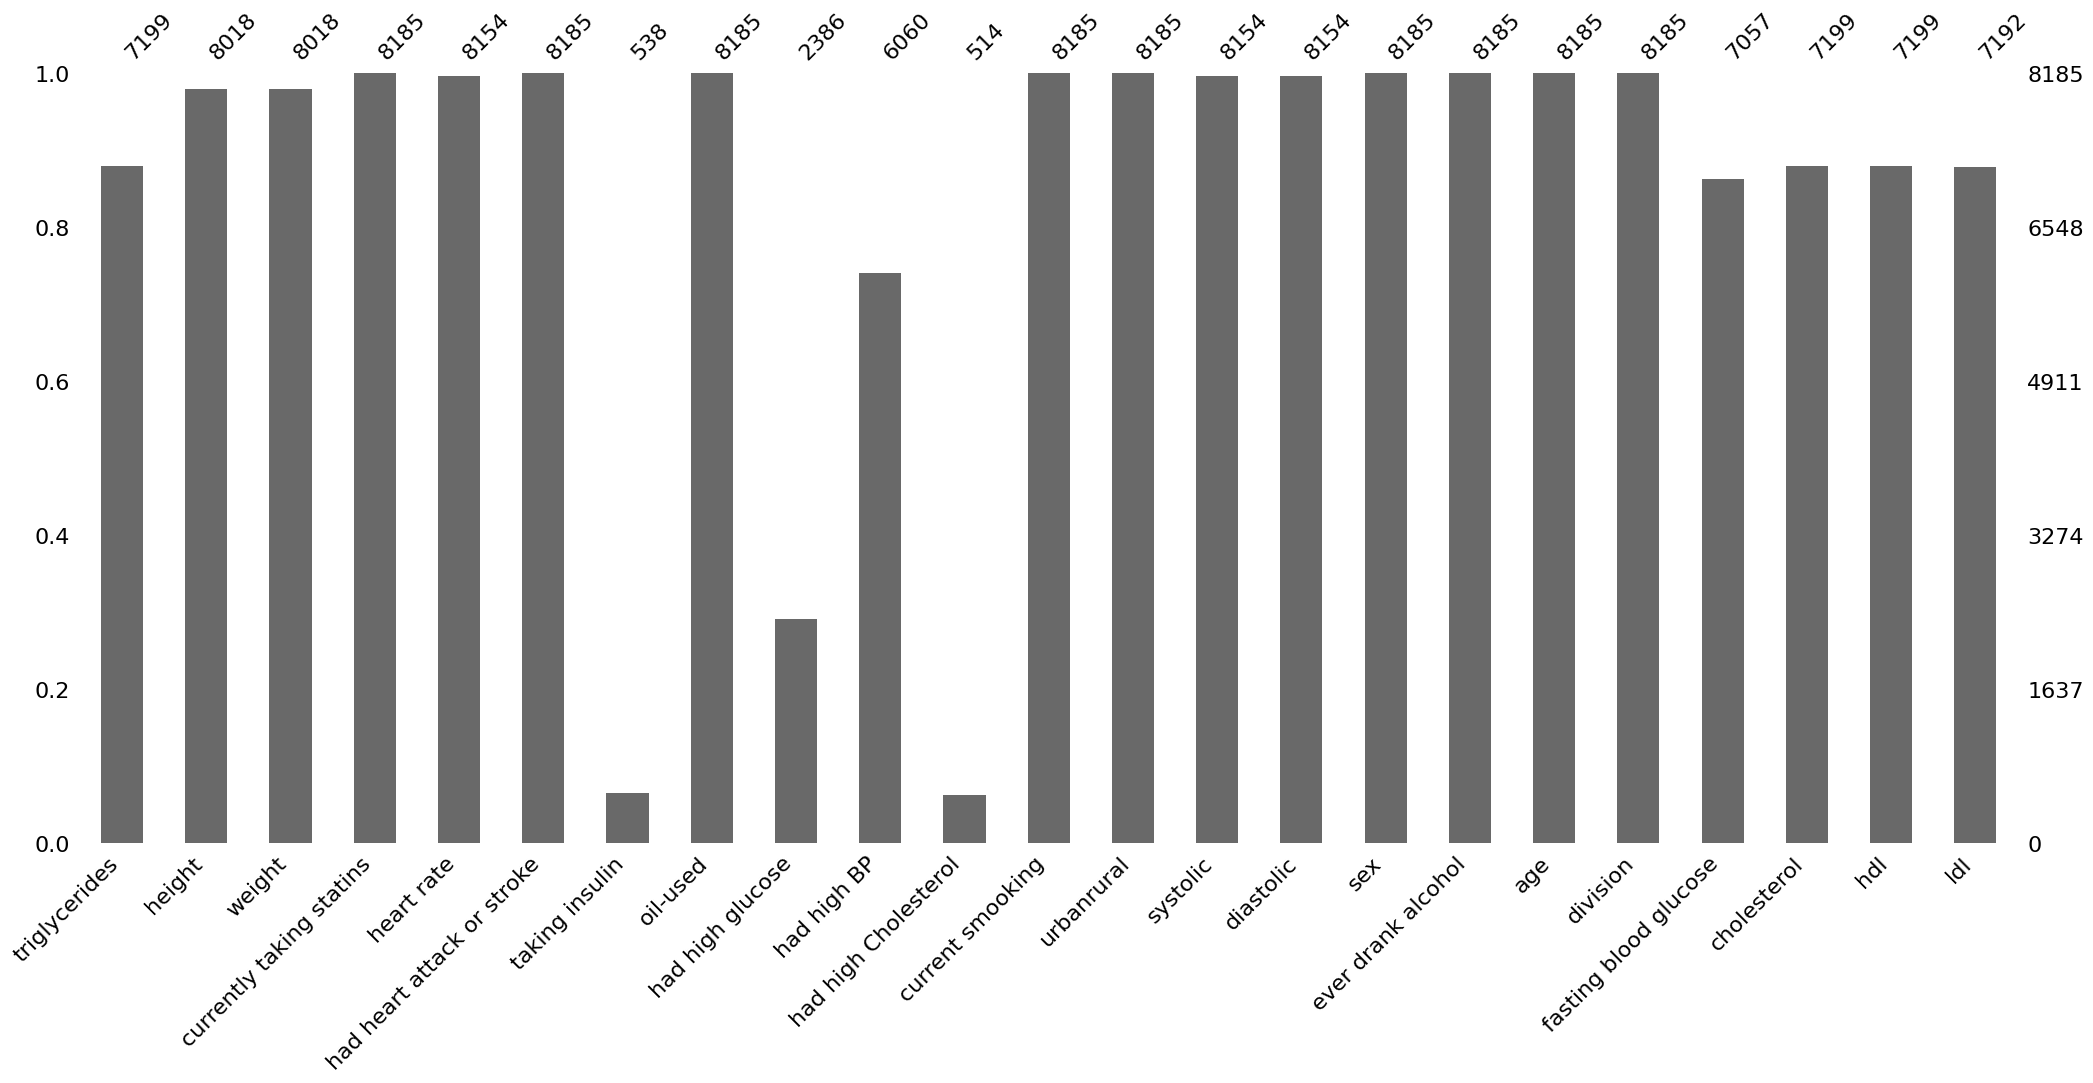

In [ ]:
msno.bar(df_ncd)
plt.show()

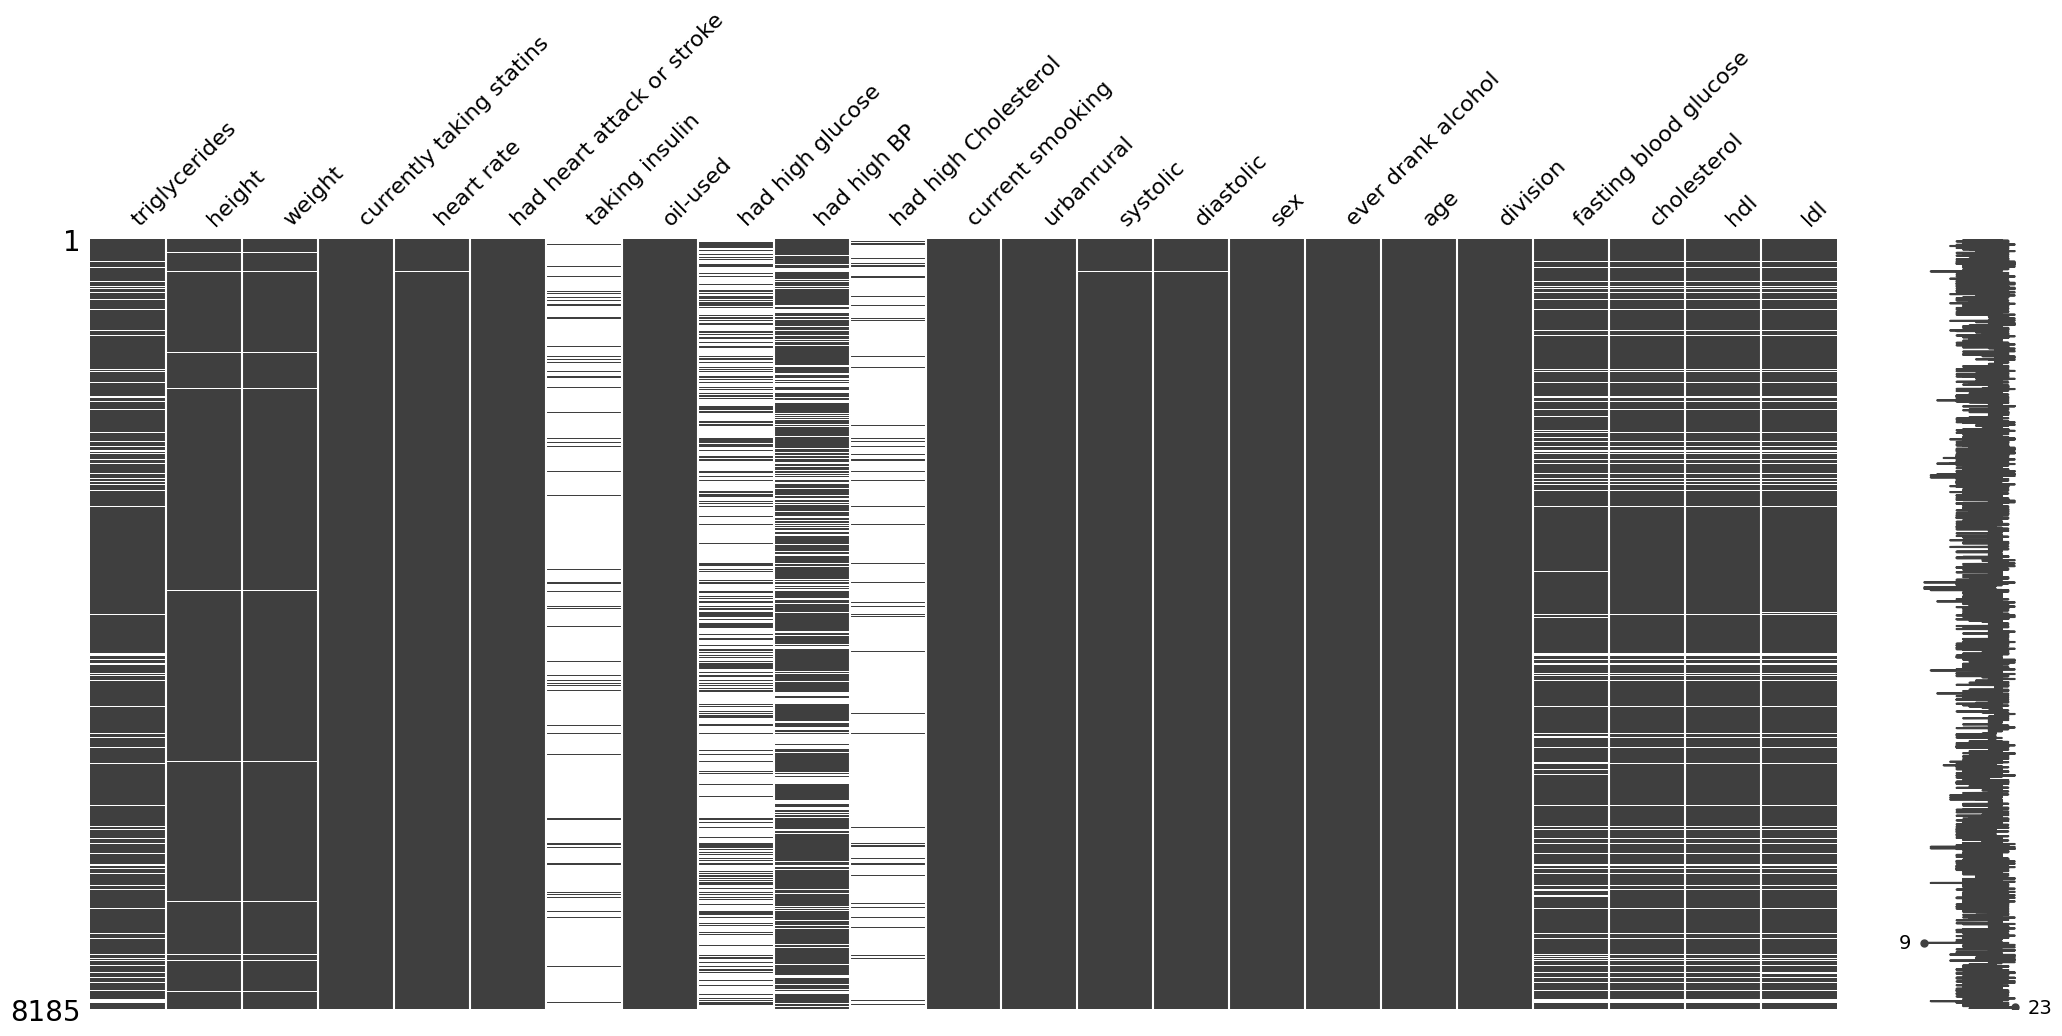

In [ ]:
msno.matrix(df_ncd)
plt.show()

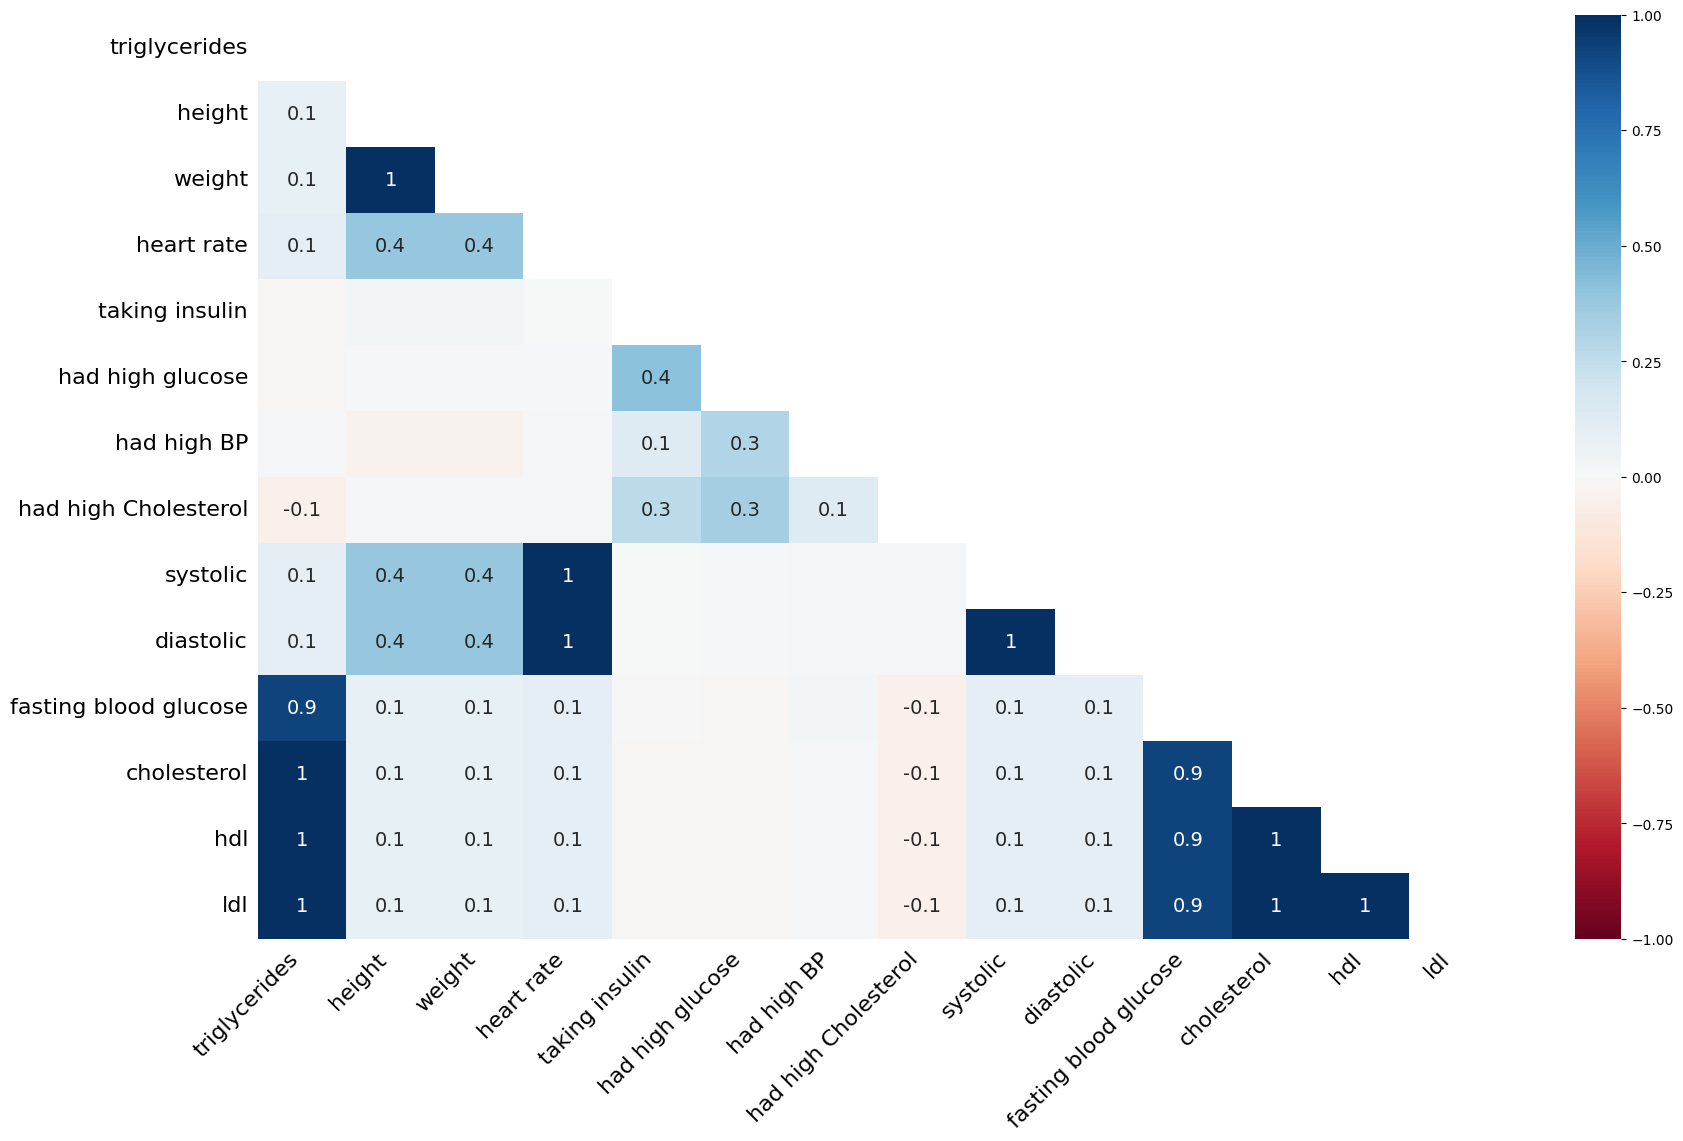

In [ ]:
msno.heatmap(df_ncd)
plt.show()

In [ ]:
# List of columns where you want to input 0 for missing values
columns_to_fill_zero = ['taking insulin', 'had high BP', 'had high Cholesterol', 'had high glucose']  # Replace with your actual column names

# Fill missing values (NaN) with 0 in the specified columns
df_ncd[columns_to_fill_zero] = df_ncd[columns_to_fill_zero].fillna(0)

# Show the updated data to verify
print(df_ncd[columns_to_fill_zero].isnull().sum())  # Check if there are any remaining NaN values



taking insulin          0
had high BP             0
had high Cholesterol    0
had high glucose        0
dtype: int64


In [ ]:
# List of columns where you want to replace missing values with the mean
columns_to_fill_mean = ['triglycerides', 'height', 'weight', 'heart rate',
                        'cholesterol', 'systolic', 'diastolic',
                        'fasting blood glucose', 'hdl', 'ldl']

# Replace missing values with the mean for each specified column
for column in columns_to_fill_mean:
    df_ncd[column] = df_ncd[column].fillna(df_ncd[column].mean())

# Verify by checking if there are still any missing values in these columns
print(df_ncd[columns_to_fill_mean].isnull().sum())  # Should return 0 for all

triglycerides            0
height                   0
weight                   0
heart rate               0
cholesterol              0
systolic                 0
diastolic                0
fasting blood glucose    0
hdl                      0
ldl                      0
dtype: int64


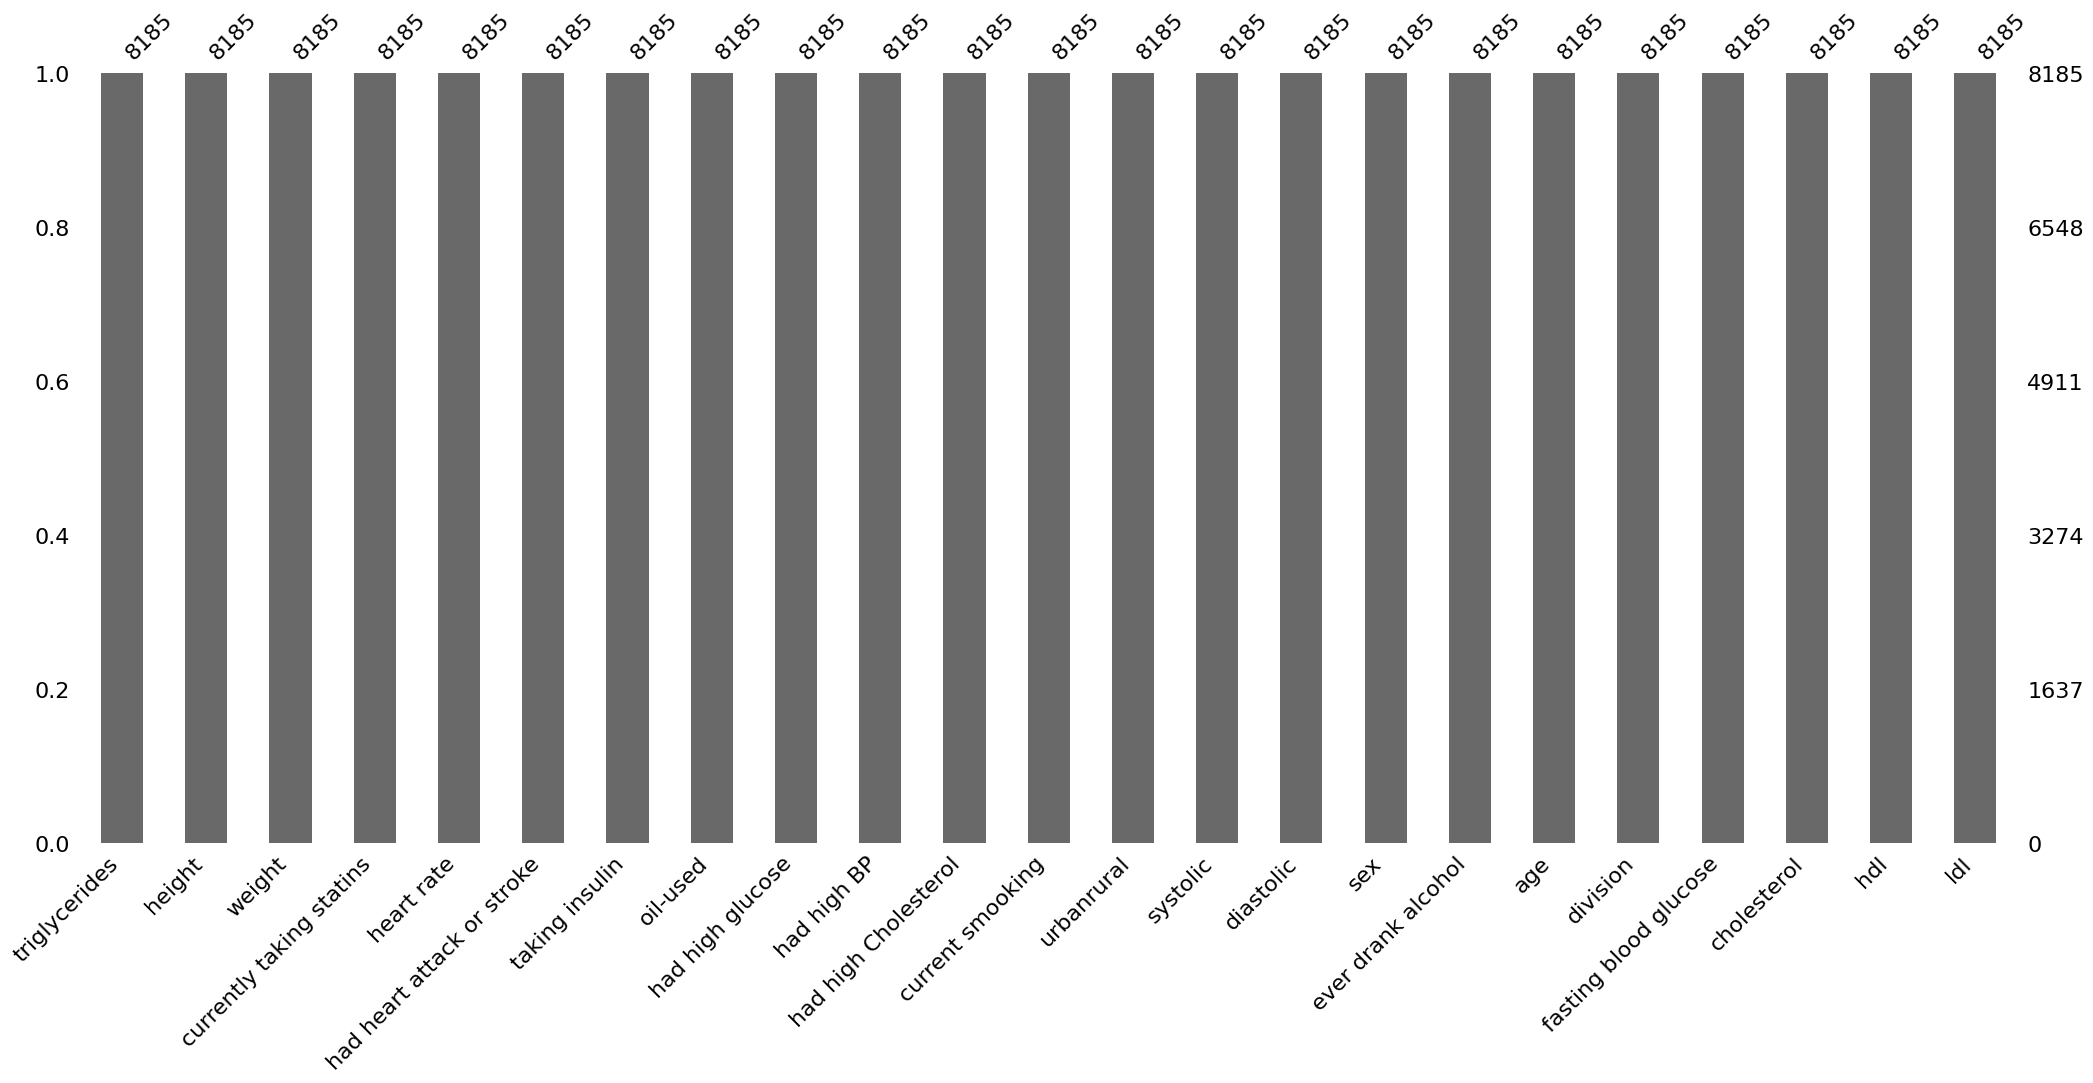

In [ ]:
msno.bar(df_ncd)
plt.show()

In [ ]:
(df_ncd.isnull().sum())*100/len(df_ncd)

,0
triglycerides,0.000
height,0.000
weight,0.000
currently taking statins,0.000
heart rate,0.000
had heart attack or stroke,0.000
taking insulin,0.000
oil-used,0.000
had high glucose,0.000
had high BP,0.000


In [ ]:
df_ncd.duplicated().sum()

0

In [ ]:
pip install pandas seaborn matplotlib


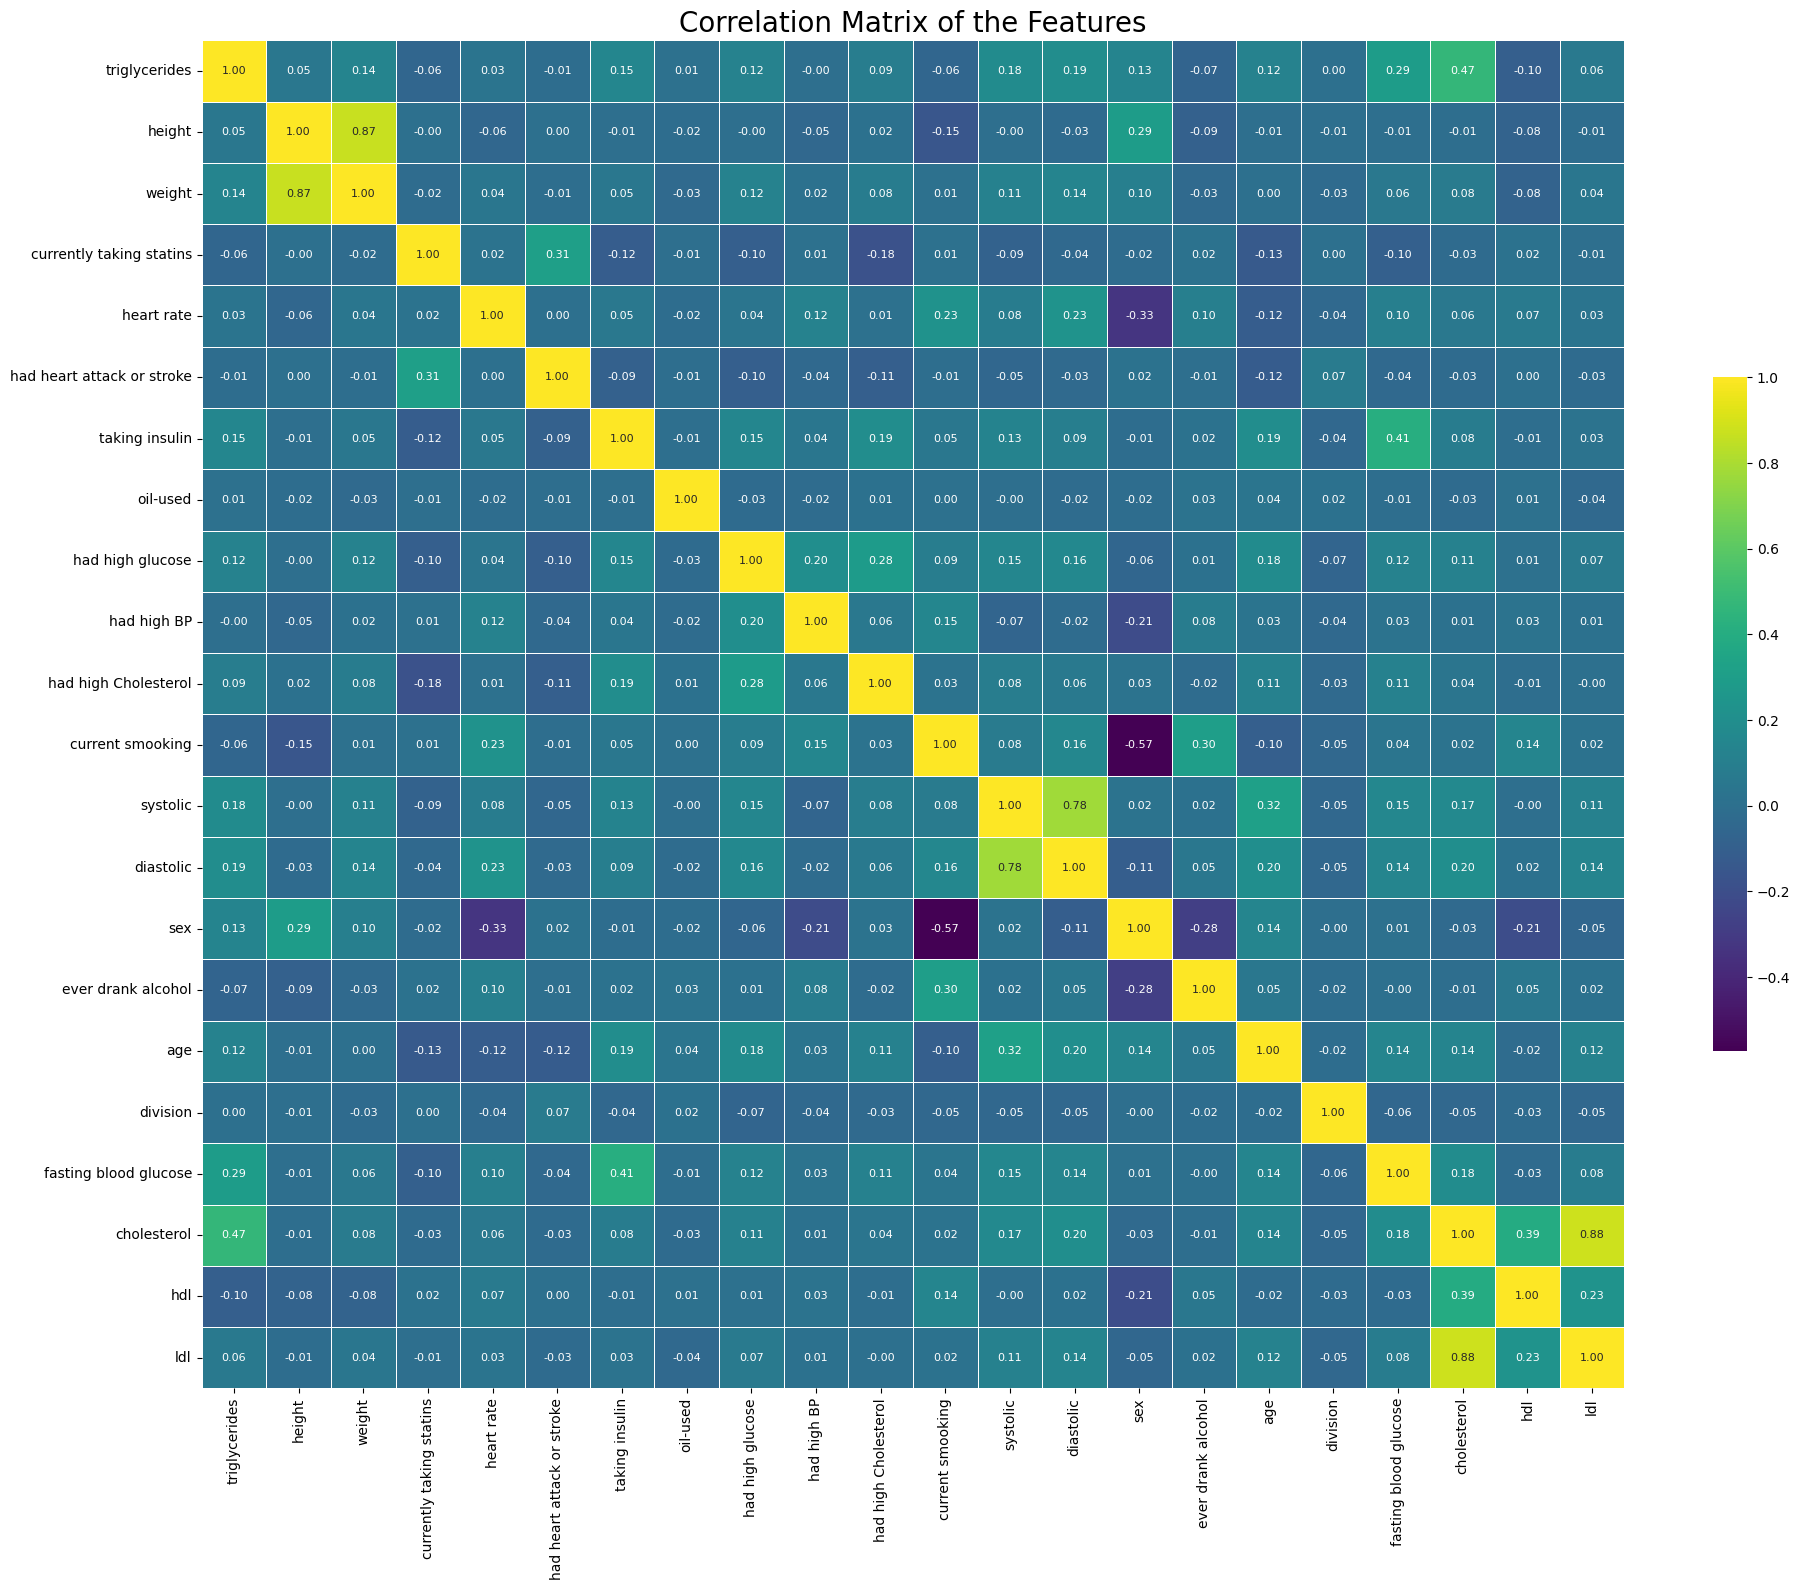

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix
df = df_ncd
# Select only numerical columns for correlation calculation
numerical_df = df.select_dtypes(include=['number'])
correlation_matrix = numerical_df.corr()

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(20, 16))
heatmap = sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='viridis', linewidths=0.5, cbar_kws={'shrink': .5}, annot_kws={"size": 8})
plt.title('Correlation Matrix of the Features', fontsize=20)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()  # Adjust layout to ensure everything fits without overlap
plt.show()

In [ ]:
df_ncd.shape

(8185, 23)

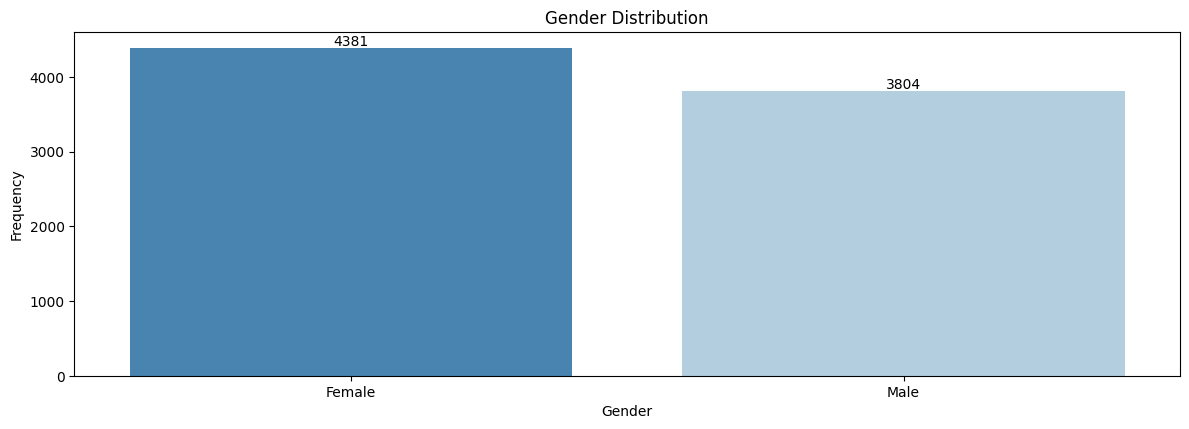

In [ ]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Renaming 'sex' column values for clarity (0: Female, 1: Male)
df_ncd['sex'] = df_ncd['sex'].replace({0: 'Female', 1: 'Male'})

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar charts similar to the image layout
plt.figure(figsize=(12, 12))

# 1. Gender distribution
plt.subplot(3, 1, 1)
ax1 = sns.countplot(x='sex', data=df_ncd, palette='Blues_r')
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Frequency')
annotate_barplot(ax1)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


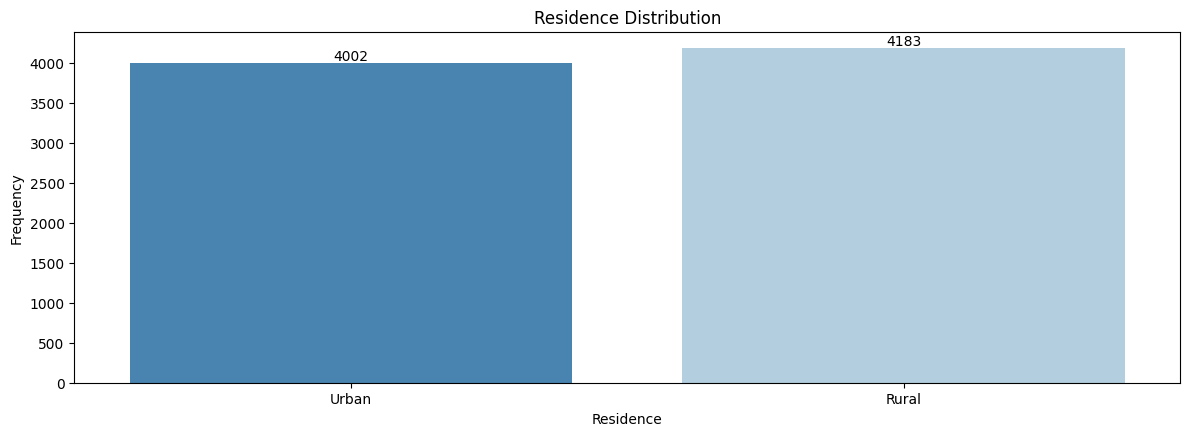

In [ ]:

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar charts similar to the image layout
plt.figure(figsize=(12, 12))

# 2. Urban vs Rural distribution
plt.subplot(3, 1, 2)
ax2 = sns.countplot(x='urbanrural', data=df_ncd, palette='Blues_r')
plt.title('Residence Distribution')
plt.xlabel('Residence')
plt.ylabel('Frequency')
annotate_barplot(ax2)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()

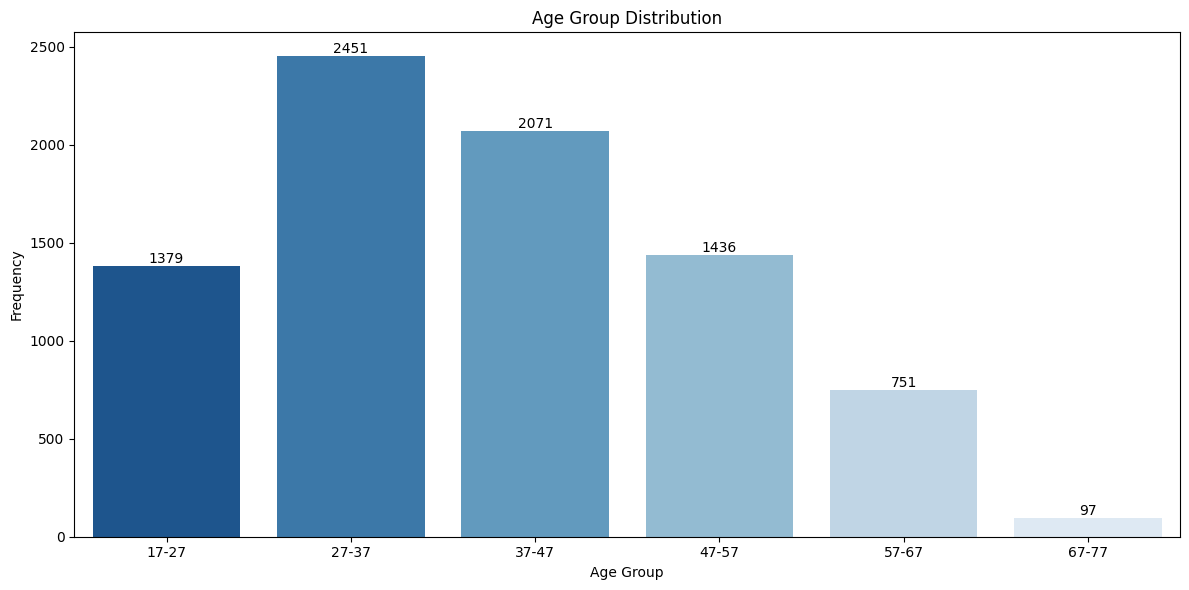

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create age bins (17-27, 27-37, etc.) and add a new 'age_group' column
age_bins = [17, 27, 37, 47, 57, 67, 77]
age_labels = ['17-27', '27-37', '37-47', '47-57', '57-67', '67-77']
df_ncd['age_group'] = pd.cut(df_ncd['age'], bins=age_bins, labels=age_labels, right=False)

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar chart for age group distribution
plt.figure(figsize=(12, 6))

# Age group distribution
ax = sns.countplot(x='age_group', data=df_ncd, palette='Blues_r')
plt.title('Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Frequency')
annotate_barplot(ax)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


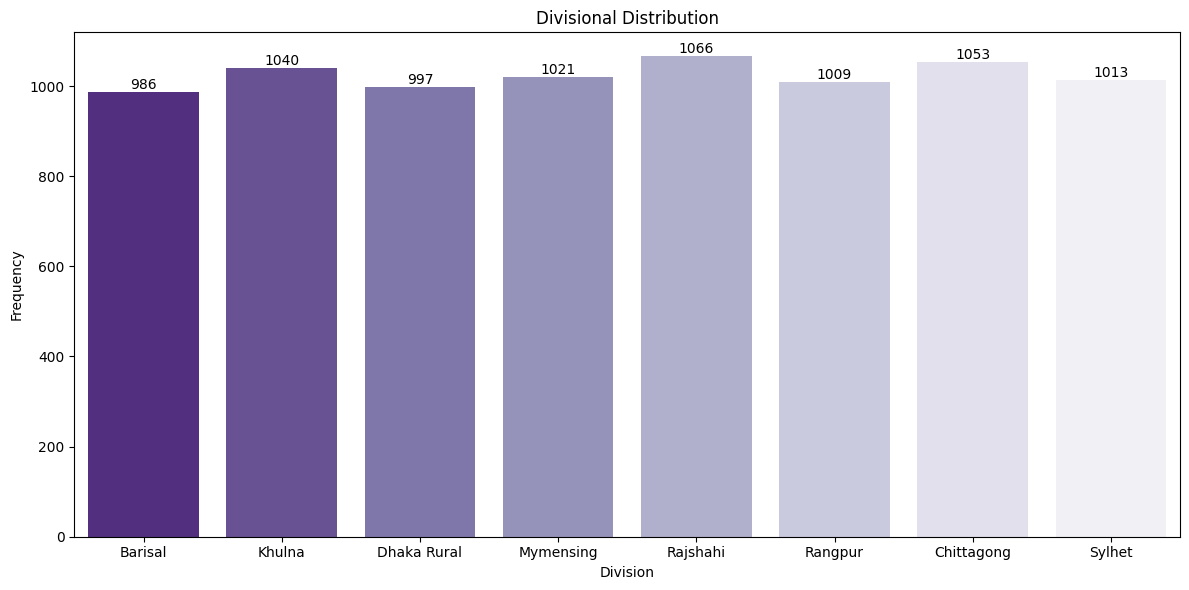

In [ ]:
# Create a dictionary for division mapping
division_mapping = {
    1: 'Barisal',
    2: 'Chittagong',
    3: 'Dhaka Rural',
    4: 'Khulna',
    5: 'Mymensing',
    6: 'Rajshahi',
    7: 'Rangpur',
    8: 'Sylhet'
}

# Assuming 'division_code' is the column in the dataset representing division
df_ncd['division'] = df_ncd['division'].map(division_mapping)

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar chart for division distribution
plt.figure(figsize=(12, 6))

# Division distribution
ax = sns.countplot(x='division', data=df_ncd, palette='Purples_r')
plt.title('Divisional Distribution')
plt.xlabel('Division')
plt.ylabel('Frequency')
annotate_barplot(ax)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


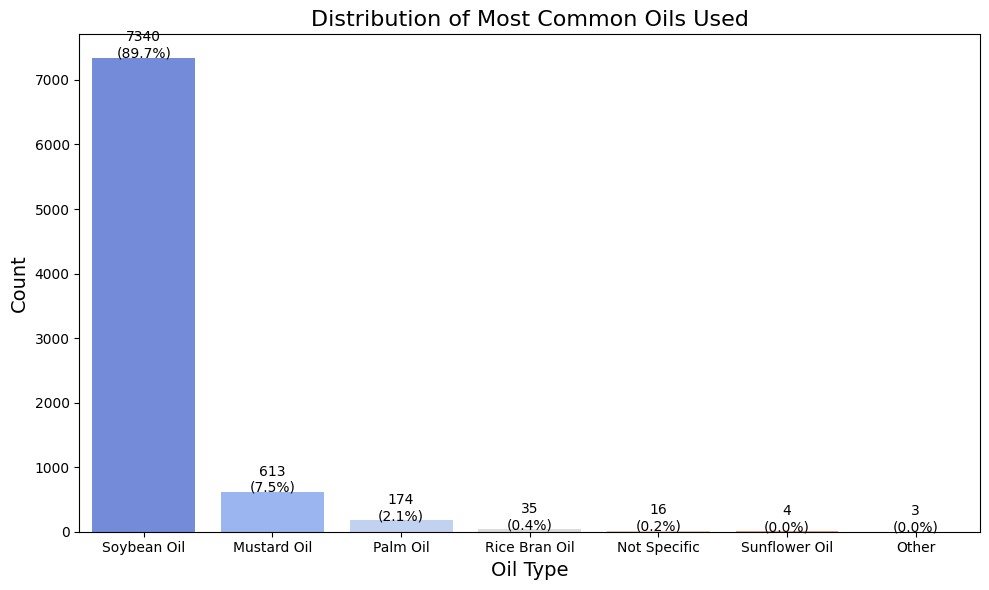

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df_ncd' is your DataFrame and 'oil-used' is the column for oil used most often
# First, map the values to their corresponding categories
oil_mapping = {
    1: 'Soybean Oil',
    2: 'Palm Oil',
    3: 'Sunflower Oil',
    4: 'Mustard Oil',
    5: 'Rice Bran Oil',
    6: 'Dalda',
    7: 'Ghee/Butter',
    8: 'Not Specific',
    9: 'Other'
}

# Map the 'oil-used' column to oil categories
df_ncd['oil_used'] = df_ncd['oil-used'].map(oil_mapping)

# Count the occurrences of each category
oil_counts = df_ncd['oil_used'].value_counts()

# Plot the distribution using a bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=oil_counts.index, y=oil_counts.values, palette='coolwarm')
plt.title('Distribution of Most Common Oils Used', fontsize=16)
plt.xlabel('Oil Type', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Add the count and percentage on top of each bar
total = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()


In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load your data (assuming your DataFrame is named 'df')
# df = pd.read_csv('your_data.csv') # Uncomment this line to load your dataset

# Define the features to be used for clustering
features = [
    'taking insulin', 'had high glucose', 'had high BP', 'had high Cholesterol',
    'triglycerides', 'height', 'weight', 'heart rate', 'cholesterol',
    'systolic', 'diastolic', 'fasting blood glucose', 'hdl', 'ldl'
]

# Ensure missing binary values are set to 0 as per your previous approach
binary_features = [
    'taking insulin', 'had high glucose', 'had high BP', 'had high Cholesterol'
]

# Mapping categorical risk features: 1 for high risk, 2 for no risk, 0 for no effect
df_ncd[binary_features] = df_ncd[binary_features].replace({2: -1, 1: 1, 0: 0})

# Standardize features to incorporate safe ranges
# For each feature, we can normalize the values based on safe range limits
safe_ranges = {
    'height': (1.5, 2.0),  # Example range in meters; adjust as per your data units
    'weight': (50, 100),  # Example range in kg; adjust based on safe BMI
    'heart rate': (60, 80),  # Optimal heart rate
    'systolic': (90, 120),
    'diastolic': (60, 80),
    'fasting blood glucose': (70, 99),  # Normal fasting glucose
    'cholesterol': (0, 200),  # Safe total cholesterol
    'hdl': (60, 100),  # Healthy HDL
    'ldl': (0, 100)  # Optimal LDL
}

# Scale each feature by standardizing using StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df[features])

# Apply K-Means clustering with 3 clusters to represent High, Medium, and Low risk
kmeans = KMeans(n_clusters=3, random_state=42)
df['Risk of CVD'] = kmeans.fit_predict(df_scaled)

# Map the cluster labels to risk categories
# Assuming the cluster centers' mean values can be ranked to assign risk
cluster_centers = kmeans.cluster_centers_.mean(axis=1)
risk_mapping = dict(zip(np.argsort(cluster_centers), ['Low', 'Medium', 'High']))
df['Risk of CVD'] = df['Risk of CVD'].map(risk_mapping)

print("Clustering complete. Here is the distribution of risk categories:")
print(df['Risk of CVD'].value_counts())
print("First few rows with risk categories:")
print(df[['Risk of CVD'] + features].head())


Clustering complete. Here is the distribution of risk categories:
Risk of CVD
Low       4811
High      2939
Medium     435
Name: count, dtype: int64
First few rows with risk categories:
  Risk of CVD  taking insulin  had high glucose  had high BP  \
0         Low           0.000             0.000       -1.000   
1      Medium          -1.000             1.000       -1.000   
2         Low           0.000             0.000       -1.000   
3         Low           0.000             0.000       -1.000   
4        High           0.000             0.000       -1.000   

   had high Cholesterol  triglycerides  height  weight  heart rate  \
0                 0.000        105.000 159.300  50.000      72.000   
1                 0.000        146.602 148.600  58.000      87.000   
2                 0.000        140.000 153.500  51.000      91.000   
3                 0.000         68.000 153.800  53.000      92.000   
4                 0.000        235.000 146.300  53.000      82.000   

   chole

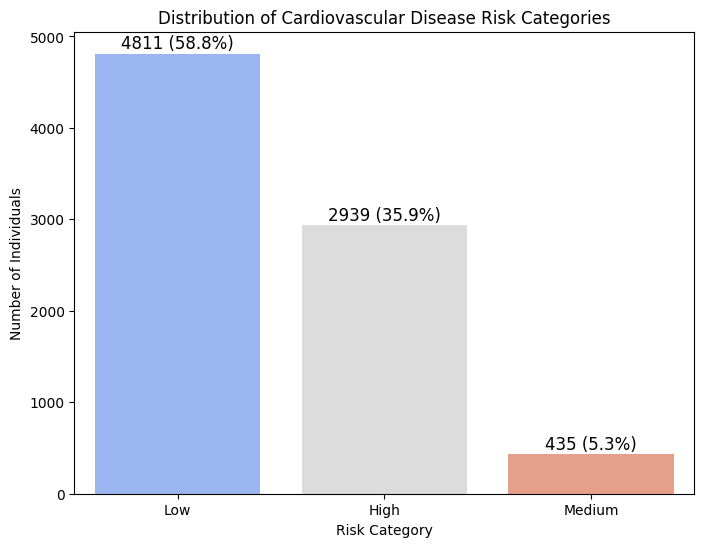

In [ ]:
# Import necessary libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each risk category and calculate percentages
risk_counts = df['Risk of CVD'].value_counts()
risk_percentages = (risk_counts / risk_counts.sum()) * 100

# Set up the plot
plt.figure(figsize=(8, 6))
sns.barplot(x=risk_counts.index, y=risk_counts.values, palette="coolwarm")

# Add titles and labels
plt.title("Distribution of Cardiovascular Disease Risk Categories")
plt.xlabel("Risk Category")
plt.ylabel("Number of Individuals")

# Add percentage and count labels on top of each bar
for i, (count, pct) in enumerate(zip(risk_counts.values, risk_percentages.values)):
    plt.text(i, count + 10, f'{count} ({pct:.1f}%)', ha='center', va='bottom', fontsize=12)

plt.xticks(rotation=0)
plt.show()



In [ ]:
# Separate data into High, Medium, and Low risk categories
high_risk = df[df['Risk of CVD'] == 'High']
medium_risk = df[df['Risk of CVD'] == 'Medium']
low_risk = df[df['Risk of CVD'] == 'Low']

# Calculate descriptive statistics for each risk category
high_risk_stats = high_risk[features].describe()
medium_risk_stats = medium_risk[features].describe()
low_risk_stats = low_risk[features].describe()

# Display the statistics for each risk category
print("High Risk Category Statistics:")
print(high_risk_stats)

print("\nMedium Risk Category Statistics:")
print(medium_risk_stats)

print("\nLow Risk Category Statistics:")
print(low_risk_stats)


High Risk Category Statistics:
       taking insulin  had high glucose  had high BP  had high Cholesterol  \
count        2939.000          2939.000     2939.000              2939.000   
mean            0.029            -0.321       -0.103                 0.009   
std             0.167             0.524        0.872                 0.286   
min             0.000            -1.000       -1.000                -1.000   
25%             0.000            -1.000       -1.000                 0.000   
50%             0.000             0.000        0.000                 0.000   
75%             0.000             0.000        1.000                 0.000   
max             1.000             1.000        1.000                 1.000   

       triglycerides   height   weight  heart rate  cholesterol  systolic  \
count       2939.000 2939.000 2939.000    2939.000     2939.000  2939.000   
mean         187.546  157.850   62.532      80.958      196.089   133.672   
std          114.346   31.533   36.

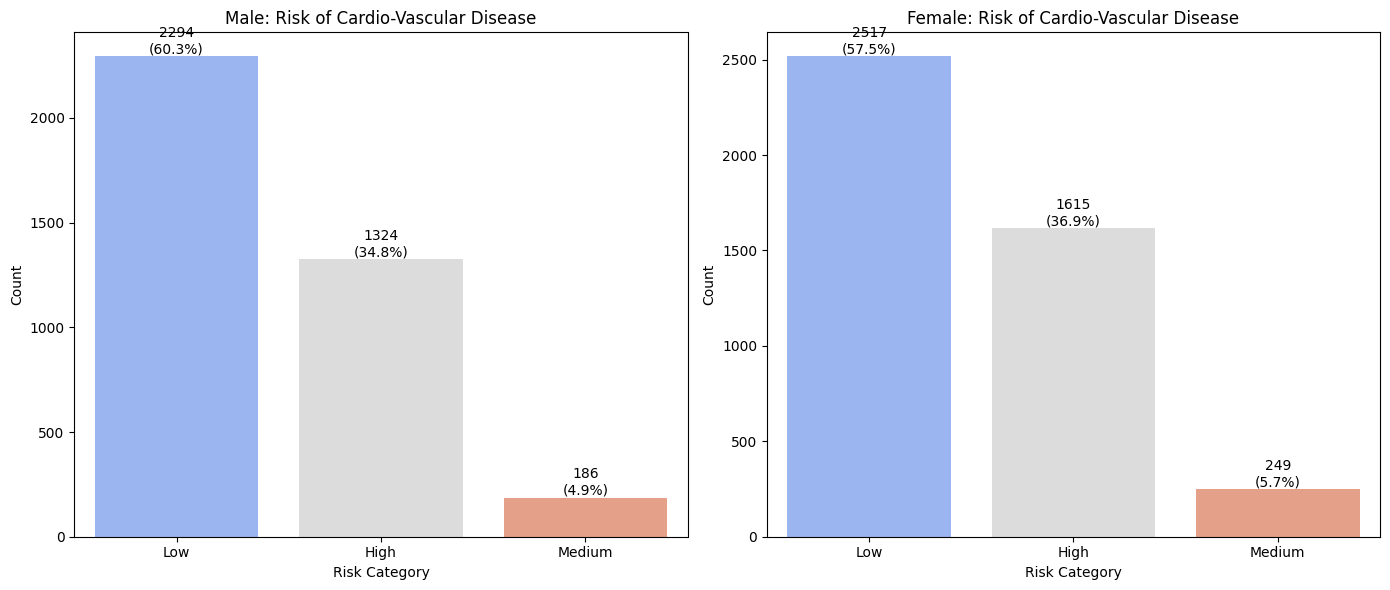

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_ncd has 'sex' and 'Risk of CVD' columns
# Separate data for male and female
male_data = df_ncd[df_ncd['sex'] == 'Male']
female_data = df_ncd[df_ncd['sex'] == 'Female']

# Calculate counts and percentages for each category
male_counts = male_data['Risk of CVD'].value_counts()
male_percentages = male_data['Risk of CVD'].value_counts(normalize=True) * 100

female_counts = female_data['Risk of CVD'].value_counts()
female_percentages = female_data['Risk of CVD'].value_counts(normalize=True) * 100

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Male Risk of CVD (Counts and Percentages)
sns.barplot(x=male_counts.index, y=male_counts.values, ax=axes[0], palette='coolwarm')
axes[0].set_title('Male: Risk of Cardio-Vascular Disease')
axes[0].set_xlabel('Risk Category')
axes[0].set_ylabel('Count')

# Adding count and percentage labels for males
for i, count in enumerate(male_counts):
    axes[0].text(i, count + 1, f'{count}\n({male_percentages[i]:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

# Female Risk of CVD (Counts and Percentages)
sns.barplot(x=female_counts.index, y=female_counts.values, ax=axes[1], palette='coolwarm')
axes[1].set_title('Female: Risk of Cardio-Vascular Disease')
axes[1].set_xlabel('Risk Category')
axes[1].set_ylabel('Count')

# Adding count and percentage labels for females
for i, count in enumerate(female_counts):
    axes[1].text(i, count + 1, f'{count}\n({female_percentages[i]:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

plt.tight_layout()
plt.show()


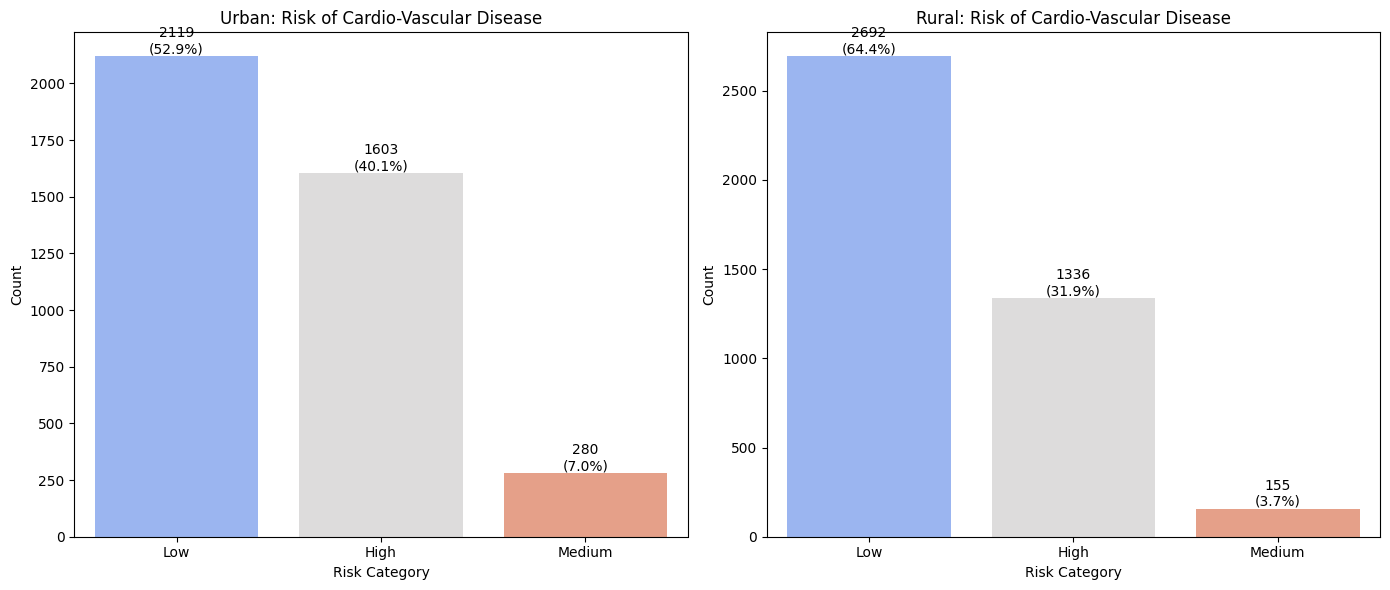

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Separate data for urban and rural categories
urban_data = df_ncd[df_ncd['urbanrural'] == 'Urban']  # or df_ncd['urbanrural'] == 1
rural_data = df_ncd[df_ncd['urbanrural'] == 'Rural']  # or df_ncd['urbanrural'] == 2

# Calculate counts and percentages for each category
urban_counts = urban_data['Risk of CVD'].value_counts()
urban_percentages = urban_data['Risk of CVD'].value_counts(normalize=True) * 100

rural_counts = rural_data['Risk of CVD'].value_counts()
rural_percentages = rural_data['Risk of CVD'].value_counts(normalize=True) * 100

# Plotting counts and percentages for each risk category in Urban and Rural
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Urban Risk of CVD (Counts and Percentages)
sns.barplot(x=urban_counts.index, y=urban_counts.values, ax=axes[0], palette='coolwarm')
axes[0].set_title('Urban: Risk of Cardio-Vascular Disease')
axes[0].set_xlabel('Risk Category')
axes[0].set_ylabel('Count')

# Adding count and percentage labels for Urban data
for i, count in enumerate(urban_counts):
    percentage = urban_percentages[i]
    axes[0].text(i, count + 1, f'{count}\n({percentage:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

# Rural Risk of CVD (Counts and Percentages)
sns.barplot(x=rural_counts.index, y=rural_counts.values, ax=axes[1], palette='coolwarm')
axes[1].set_title('Rural: Risk of Cardio-Vascular Disease')
axes[1].set_xlabel('Risk Category')
axes[1].set_ylabel('Count')

# Adding count and percentage labels for Rural data
for i, count in enumerate(rural_counts):
    percentage = rural_percentages[i]
    axes[1].text(i, count + 1, f'{count}\n({percentage:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

plt.tight_layout()
plt.show()


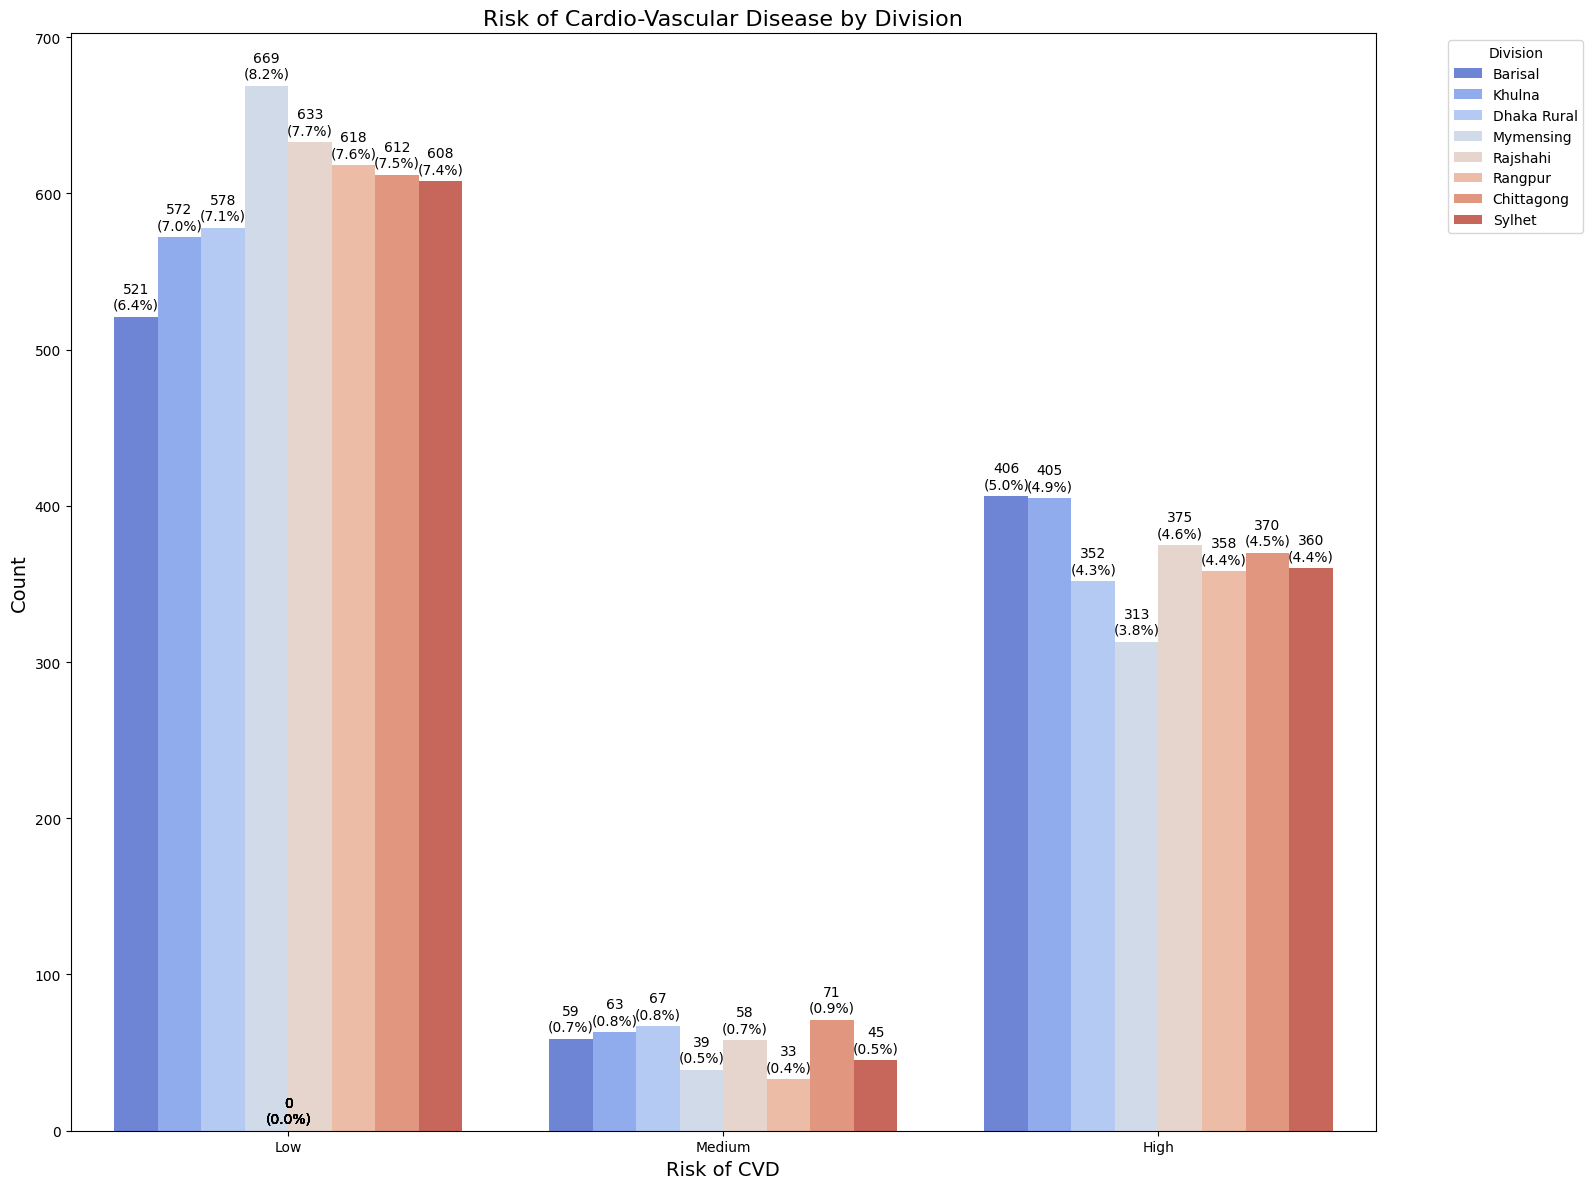

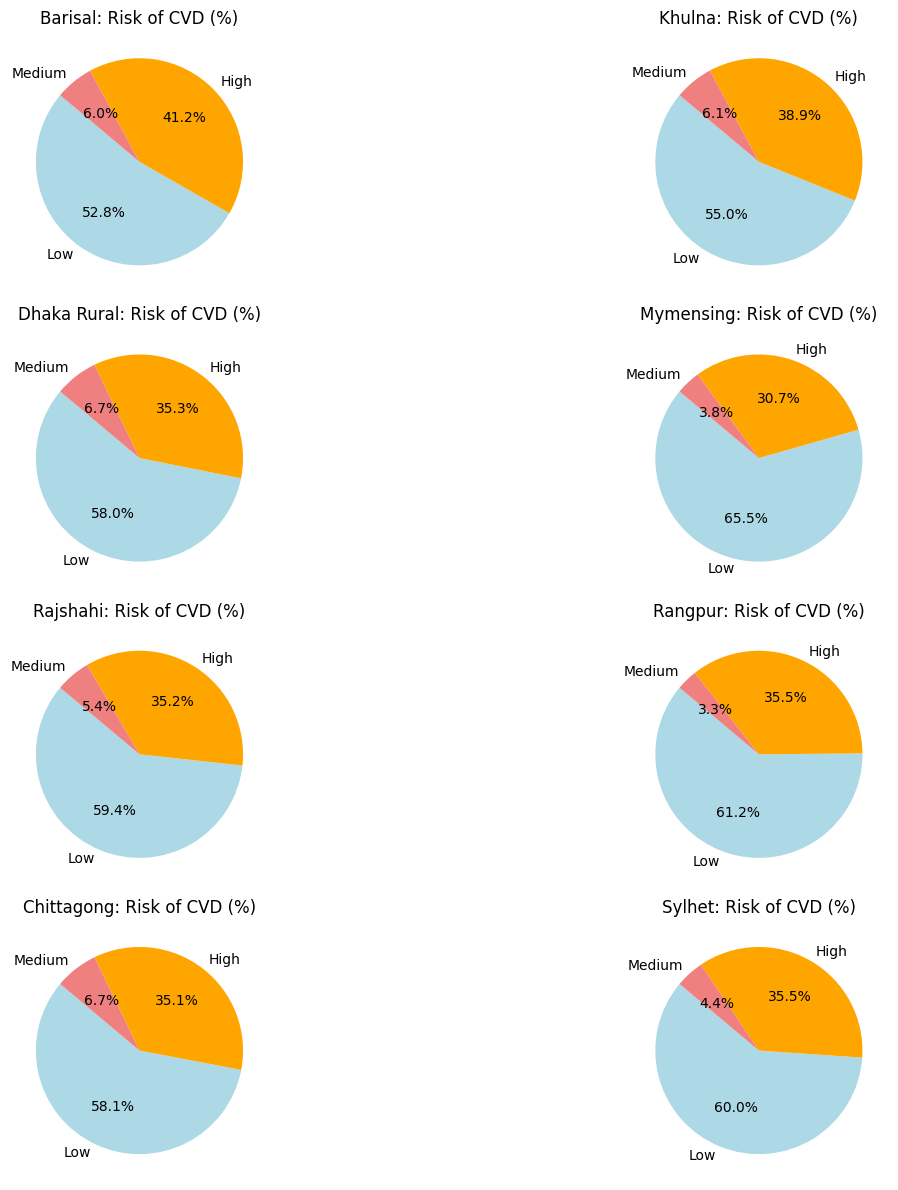

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across divisions
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of CVD', hue='division', data=df_ncd, palette='coolwarm')
plt.title('Risk of Cardio-Vascular Disease by Division', fontsize=16)
plt.xlabel('Risk of CVD', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='Division', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each division
divisions = df_ncd['division'].unique()
num_divisions = len(divisions)
plt.figure(figsize=(16, 12))

for idx, division in enumerate(divisions, 1):
    division_data = df_ncd[df_ncd['division'] == division]
    division_counts = division_data['Risk of CVD'].value_counts()

    plt.subplot((num_divisions + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(division_counts, labels=division_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{division}: Risk of CVD (%)')

plt.tight_layout()
plt.show()


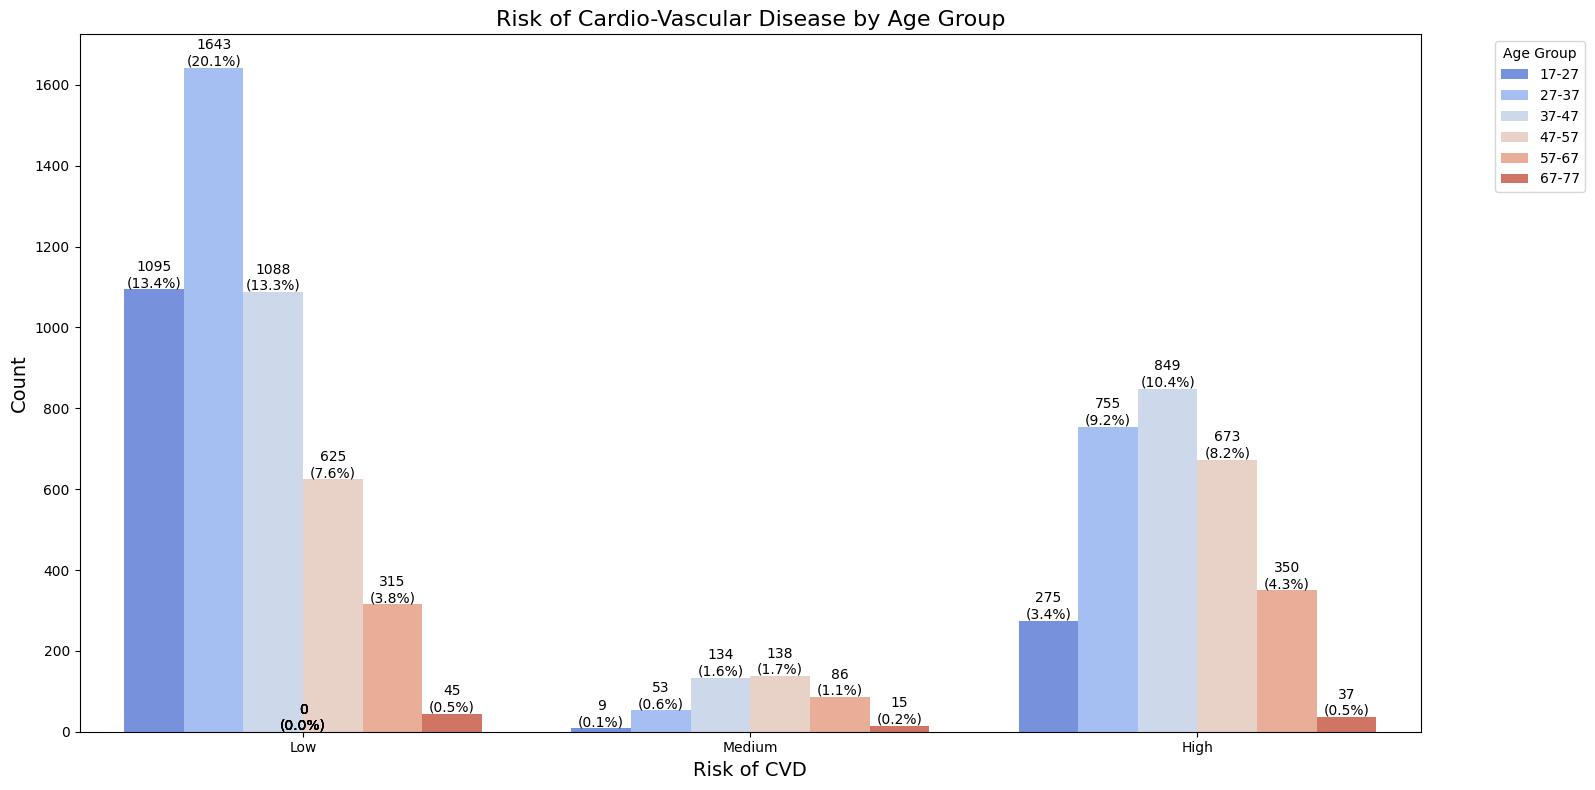

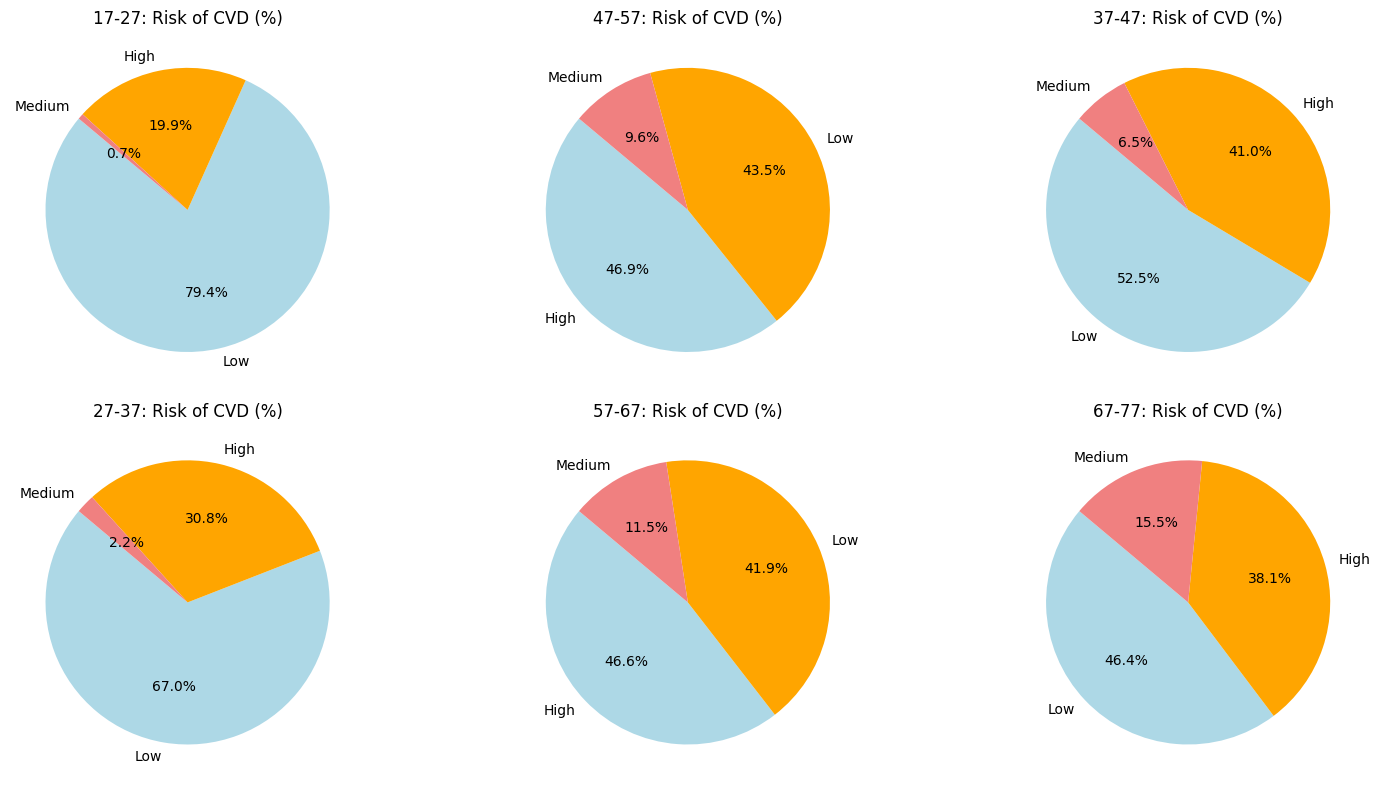

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Step 1: Create age groups
age_bins = [17, 27, 37, 47, 57, 67, 77]  # Age bin boundaries
age_labels = ['17-27', '27-37', '37-47', '47-57', '57-67', '67-77']  # Age group labels

# Add the age group column to the dataset
df_ncd['age_group'] = pd.cut(df_ncd['age'], bins=age_bins, labels=age_labels, right=False)

# Step 2: Overall count plot with counts and percentages
plt.figure(figsize=(16, 8))
sns.countplot(x='Risk of CVD', hue='age_group', data=df_ncd, palette='coolwarm')
plt.title('Risk of Cardio-Vascular Disease by Age Group', fontsize=16)
plt.xlabel('Risk of CVD', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='Age Group', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Step 3: Pie charts for each age group
age_groups = df_ncd['age_group'].unique()
num_age_groups = len(age_groups)
plt.figure(figsize=(16, 8))

for idx, age_group in enumerate(age_groups, 1):
    age_group_data = df_ncd[df_ncd['age_group'] == age_group]
    age_group_counts = age_group_data['Risk of CVD'].value_counts()

    plt.subplot((num_age_groups + 2) // 3, 3, idx)  # Arrange pie charts in a grid
    plt.pie(age_group_counts, labels=age_group_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{age_group}: Risk of CVD (%)')

plt.tight_layout()
plt.show()


In [ ]:
#Smote

In [ ]:
from sklearn.model_selection import train_test_split

# Define X (features) and y (target)
X = df_ncd[features]  # Features from clustering
y = df_ncd['Risk of CVD']  # Target variable

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report

# Dictionary to store models and their names
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42)
}

# Dictionary to hold evaluation results
results = {}

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)  # Train model
    y_pred = model.predict(X_test)  # Make predictions on test set

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')

    # Store results
    results[name] = {
        'Accuracy': accuracy,
        'F1 Score': f1,
        'Precision': precision,
        'Recall': recall
    }
    # Print classification report for each model
    print(f"Classification Report for {name}:\n", classification_report(y_test, y_pred))


Classification Report for Logistic Regression:
               precision    recall  f1-score   support

        High       0.88      0.86      0.87       573
         Low       0.92      0.93      0.93       995
      Medium       0.97      0.99      0.98        69

    accuracy                           0.91      1637
   macro avg       0.92      0.93      0.92      1637
weighted avg       0.91      0.91      0.91      1637

Classification Report for K-Nearest Neighbors:
               precision    recall  f1-score   support

        High       0.82      0.82      0.82       573
         Low       0.89      0.93      0.91       995
      Medium       0.35      0.12      0.17        69

    accuracy                           0.86      1637
   macro avg       0.69      0.62      0.64      1637
weighted avg       0.84      0.86      0.85      1637

Classification Report for Decision Tree:
               precision    recall  f1-score   support

        High       0.89      0.89      0.89  

In [ ]:
import pandas as pd

# Convert results to DataFrame
results_df = pd.DataFrame(results).T  # Transpose for easier viewing
print(results_df)


                        Accuracy  F1 Score  Precision  Recall
Logistic Regression        0.908     0.908      0.908   0.908
K-Nearest Neighbors        0.859     0.848      0.844   0.859
Decision Tree              0.923     0.923      0.923   0.923
Random Forest              0.961     0.961      0.961   0.961
Support Vector Machine     0.899     0.886      0.887   0.899


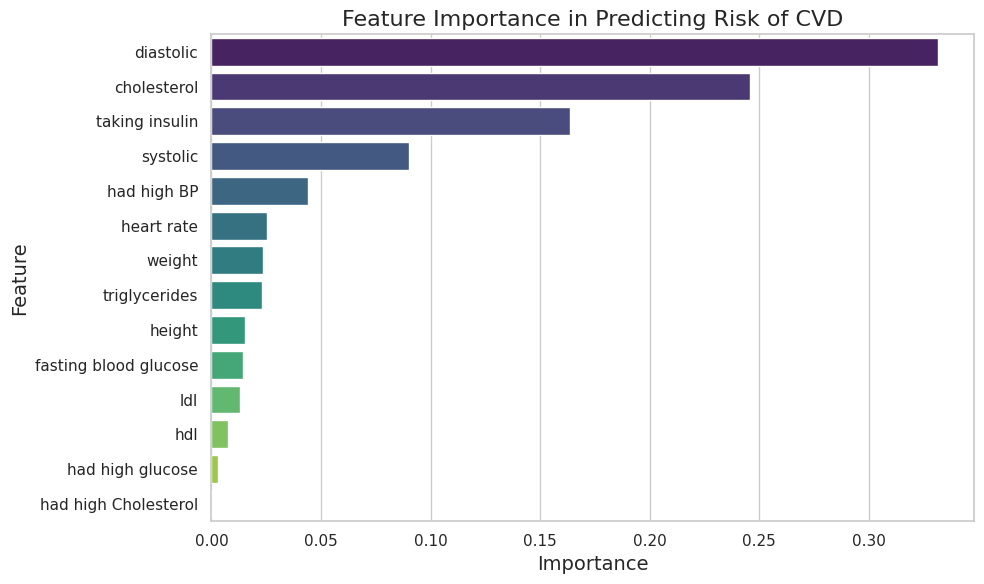

Feature Importance (sorted):
                  Feature  Importance
10              diastolic       0.331
8             cholesterol       0.246
0          taking insulin       0.164
9                systolic       0.090
2             had high BP       0.044
7              heart rate       0.025
6                  weight       0.023
4           triglycerides       0.023
5                  height       0.016
11  fasting blood glucose       0.014
13                    ldl       0.013
12                    hdl       0.008
1        had high glucose       0.003
3    had high Cholesterol       0.000


In [ ]:
# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load your dataset (replace with the actual path to your file)
# df_ncd = pd.read_csv('path_to_your_data.csv')  # Replace with the correct path

# Example: Define features and target (make sure these match your dataset columns)
features = [
    'taking insulin', 'had high glucose', 'had high BP', 'had high Cholesterol',
    'triglycerides', 'height', 'weight', 'heart rate', 'cholesterol',
    'systolic', 'diastolic', 'fasting blood glucose', 'hdl', 'ldl'
]

# Step 2: Separate features (X) and target variable (y)
X = df_ncd[features]  # Select features
y = df_ncd['Risk of CVD']  # Assuming 'Risk of CVD' is your target column

# Step 3: Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Step 4: Train a decision tree classifier
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# Step 5: Get feature importances
importances = clf.feature_importances_

# Step 6: Create a DataFrame to view feature importance
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
})

# Step 7: Sort the features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Step 8: Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Feature Importance in Predicting Risk of CVD', fontsize=16)
plt.xlabel('Importance', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.tight_layout()
plt.show()

# Print the sorted importance values
print("Feature Importance (sorted):")
print(importance_df)


In [ ]:
#Grid